## Ćwiczenie 9: Dodatek do analiza widmowa obrazów

Ten notatnik demonstruje dwa fascynujące zjawiska związane z analizą częstotliwościową obrazów:
1. **Filtry częstotliwościowe (Rozmycie i Szkic)** - jak usunięcie konkretnych częstotliwości wpływa na obraz.
2. **Obrazy hybrydowe (Iluzja optyczna)** - jak ludzkie oko odbiera różne częstotliwości z różnej odległości.

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data, color, transform
from scipy.fft import fft2, fftshift, ifft2, ifftshift

# Pomocnicza funkcja do wyświetlania
def show_images(images, titles, figsize=(15, 5)):
    fig, axes = plt.subplots(1, len(images), figsize=figsize)
    for ax, img, title in zip(axes, images, titles):
        ax.imshow(img, cmap='gray')
        ax.set_title(title)
        ax.axis('off')
    plt.tight_layout()
    plt.show()

### 1. Rozmycie i Szkic (Filtry dolno- i górnoprzepustowe)

W widmie Fouriera:
*   **Środek (niskie częstotliwości)** odpowiada za ogólne zarysy i tło obrazu.
*   **Obrzeża (wysokie częstotliwości)** odpowiadają za detale i ostre krawędzie.

Wycięcie odpowiednich części widma pozwala nam uzyskać efekt rozmycia (zostawiamy tylko środek) lub wyciągnięcia krawędzi (zostawiamy tylko obrzeża).

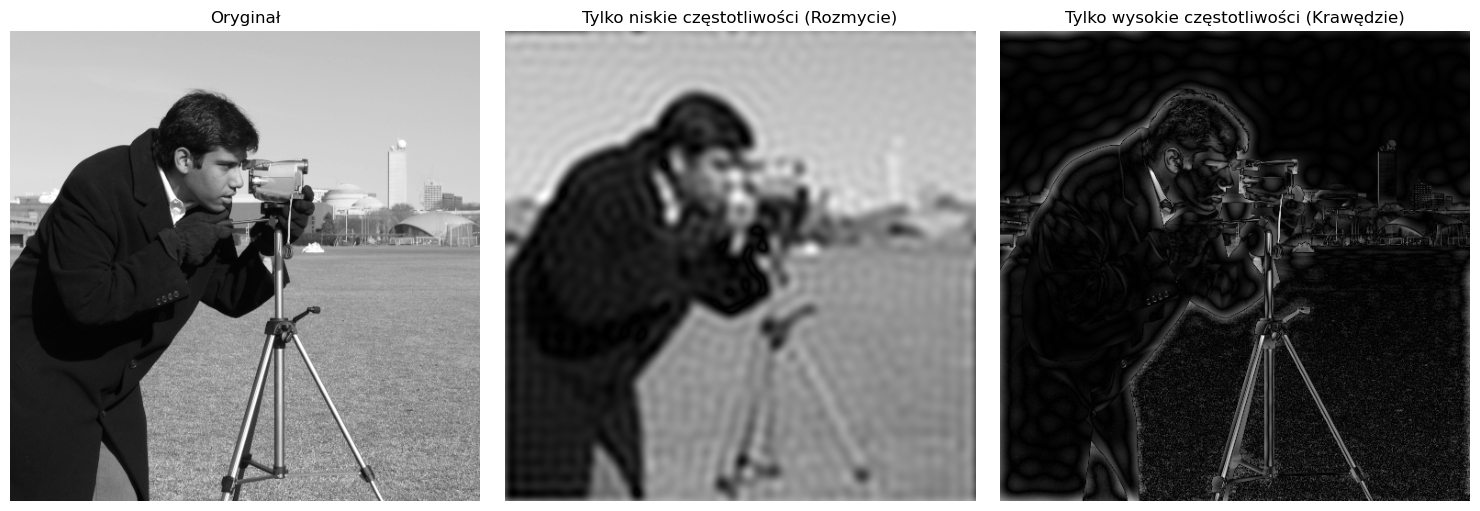

In [7]:
# Pobieramy obraz
image = data.camera()

# Widmo Fouriera
f_transform = fftshift(fft2(image))
rows, cols = image.shape
center_row, center_col = rows // 2, cols // 2

# Przygotowanie siatki współrzędnych do stworzenia okrągłej maski
Y, X = np.ogrid[:rows, :cols]
dist_from_center = np.sqrt((X - center_col)**2 + (Y - center_row)**2)

# --- 1. FILTR DOLNOPRZEPUSTOWY (ROZMYCIE) ---
# Zostawiamy tylko fale blisko środka (promień <= 30)
mask_low = dist_from_center <= 30
f_transform_low = f_transform.copy() * mask_low
img_low_pass = np.abs(ifft2(ifftshift(f_transform_low)))

# --- 2. FILTR GÓRNOPRZEPUSTOWY (SZKIC/KRAWĘDZIE) ---
# Usuwamy środek (wycinamy promień <= 15), zostawiamy resztę
mask_high = dist_from_center > 15
f_transform_high = f_transform.copy() * mask_high
img_high_pass = np.abs(ifft2(ifftshift(f_transform_high)))

# Wyświetlanie wyników
show_images([image, img_low_pass, img_high_pass], 
            ['Oryginał', 'Tylko niskie częstotliwości (Rozmycie)', 'Tylko wysokie częstotliwości (Krawędzie)'])


### 2. Obrazy hybrydowe (iluzja optyczna)

Zjawisko to wykorzystuje fakt, że ludzkie oko z bliska dostrzega wysokie częstotliwości (detale), a z daleka niskie (ogólne zarysy).

Zbudujemy obraz hybrydowy łącząc:
1.  **Obraz 1 (np. kot):** zostawiamy tylko wysokie częstotliwości (ostre kontury).
2.  **Obraz 2 (np. twarz/astronautka):** zostawiamy tylko niskie częstotliwości (rozmyta plama).

**Zadanie:** Po wyświetleniu obrazu hybrydowego, popatrz na niego z bliska, a następnie odejdź kilka metrów od monitora lub zmruż mocno oczy!

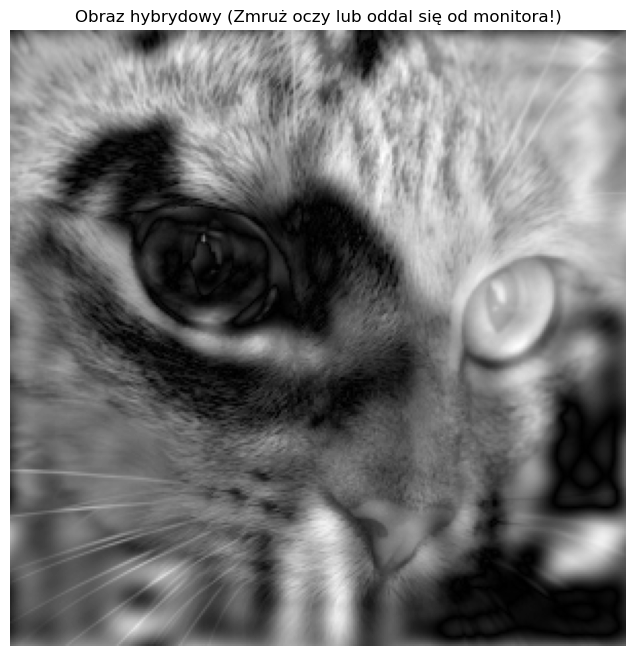

In [10]:
# 1. Wczytujemy dwa obrazy z wbudowanych datasetów skimage
img_cat = color.rgb2gray(data.chelsea())
img_face = color.rgb2gray(data.astronaut())

# Przycinamy oba obrazy do rozmiaru 300x300 i środkujemy
min_size = 300

img_cat = transform.resize(img_cat[img_cat.shape[0]//2 - min_size//2 : img_cat.shape[0]//2 + min_size//2, 
                                   img_cat.shape[1]//2 - min_size//2 : img_cat.shape[1]//2 + min_size//2], 
                           (min_size, min_size))

img_face = transform.resize(img_face[img_face.shape[0]//2 - min_size//2 : img_face.shape[0]//2 + min_size//2, 
                                     img_face.shape[1]//2 - min_size//2 : img_face.shape[1]//2 + min_size//2], 
                           (min_size, min_size))

# 2. Obliczamy widma Fouriera
f_cat = fftshift(fft2(img_cat))
f_face = fftshift(fft2(img_face))

# 3. Przygotowujemy maski
rows, cols = img_cat.shape
center_row, center_col = rows // 2, cols // 2
Y, X = np.ogrid[:rows, :cols]
dist_from_center = np.sqrt((X - center_col)**2 + (Y - center_row)**2)

# 4. Aplikujemy filtry
# Obraz 1 (Kot): Filtr górnoprzepustowy (tylko krawędzie) - r > 10
mask_high_cat = dist_from_center > 10
f_cat_high = f_cat * mask_high_cat

# Obraz 2 (Astronautka): Filtr dolnoprzepustowy (tylko rozmycie) - r <= 15
mask_low_face = dist_from_center <= 15
f_face_low = f_face * mask_low_face

# 5. Łączymy widma (dodajemy je do siebie)
f_hybrid = f_cat_high + f_face_low

# 6. Wracamy do przestrzeni pikseli
img_hybrid = np.abs(ifft2(ifftshift(f_hybrid)))

# 7. Wyświetlamy
plt.figure(figsize=(8, 8))
plt.imshow(img_hybrid, cmap='gray')
plt.title('Obraz hybrydowy (Zmruż oczy lub oddal się od monitora!)')
plt.axis('off')
plt.show()